## 1. Import thư viện

In [1]:
from pathlib import Path
import itertools
import json
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

SEED = 42

In [2]:
# Cấu hình đường dẫn theo cây thư mục project/
if Path("weather_clean.csv").exists():
    DATA_PATH = Path("weather_clean.csv")
    PROJECT_ROOT = Path(".").resolve()
else:
    PROJECT_ROOT = Path("..").resolve()
    DATA_PATH = PROJECT_ROOT / "data" / "processed" / "weather_clean.csv"

OUTPUT_DIR = PROJECT_ROOT / "results" / "lightgbm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Đọc dữ liệu

In [3]:
df_raw = pd.read_csv(DATA_PATH)
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

print("Kích thước dữ liệu:", df_raw.shape)
print("Phân bổ cột split:\n", df_raw["split"].value_counts())

Kích thước dữ liệu: (2373, 12)
Phân bổ cột split:
 split
train    1827
val       365
test      181
Name: count, dtype: int64


In [4]:
assert set(df_raw["split"].unique()) == {"train", "val", "test"}, "Cột split không khớp quy ước!"
assert len(df_raw[df_raw["split"] == "test"]) == 181, "Tập test 6 tháng đầu năm 2026 phải có đúng 181 ngày!"

## 3. Tạo đặc trưng

In [5]:
def create_lightgbm_features(
    df_in: pd.DataFrame,
    fit_mask: pd.Series = None,
    fourier_k: int = 3,
) -> tuple[pd.DataFrame, list[str]]:
    data = df_in.copy()
    doy = data["date"].dt.dayofyear

    # Nhóm 1: Đặc trưng thời gian và chuỗi Fourier bậc K=3 (9 biến)
    data["time_month"] = data["date"].dt.month
    data["time_dayofyear"] = doy
    data["time_weekofyear"] = data["date"].dt.isocalendar().week.astype(int)

    for k in range(1, fourier_k + 1):
        data[f"time_sin_{k}"] = np.sin(2.0 * np.pi * k * doy / 365.25)
        data[f"time_cos_{k}"] = np.cos(2.0 * np.pi * k * doy / 365.25)

    # Nhóm 2: Đặc trưng lag và rolling chu kỳ năm của tavg (7 biến)
    s365 = data["tavg"].shift(365)
    s730 = data["tavg"].shift(730)

    data["ar_tavg_lag_365"] = s365
    data["ar_tavg_lag_730"] = s730
    data["ar_tavg_same_day_2yr_mean"] = 0.5 * (s365 + s730)

    for win in [7, 14, 30]:
        data[f"ar_tavg_lag365_roll_mean_{win}"] = s365.rolling(window=win, min_periods=1).mean()

    data["ar_tavg_lag365_roll_std_14"] = s365.rolling(window=14, min_periods=2).std()

    feature_cols = [c for c in data.columns if c.startswith(("time_", "ar_"))]
    return data, feature_cols

## 4. Huấn luyện và tinh chỉnh siêu tham số trên tập xác thực 2025

In [6]:
df_tune, feature_cols = create_lightgbm_features(
    df_raw, fit_mask=(df_raw["split"] == "train")
)

train_df = df_tune[(df_tune["split"] == "train") & (df_tune["ar_tavg_lag_365"].notna())].reset_index(drop=True)
val_df = df_tune[df_tune["split"] == "val"].reset_index(drop=True)

X_train, y_train = train_df[feature_cols], train_df["tavg"]
X_val, y_val = val_df[feature_cols], val_df["tavg"]

In [7]:
PARAM_GRID = {
    "max_depth": [2, 3, 4],
    "num_leaves": [4, 7, 15],
    "learning_rate": [0.02, 0.03, 0.05],
    "min_child_samples": [20, 30, 50],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
    "reg_alpha": [0.1, 1.0],
    "reg_lambda": [1.0, 5.0],
}

In [8]:
keys, values = zip(*PARAM_GRID.items())
valid_combinations = [
    dict(zip(keys, bundle))
    for bundle in itertools.product(*values)
    if dict(zip(keys, bundle))["num_leaves"] <= (2 ** dict(zip(keys, bundle))["max_depth"])
]

best_val_loss = float("inf")
best_params = None
best_n_estimators = None

for params in valid_combinations:
    model = lgb.LGBMRegressor(
        objective="regression",
        n_estimators=1000,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
        **params,
    )
    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="rmse",
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
    )
    val_loss = model.best_score_["valid_0"]["rmse"]

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_params = params.copy()
        best_n_estimators = int(model.best_iteration_)

/opt/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/opt/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/opt/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/opt/anaconda3/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=

=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (2025) ===
Validation MAE  : 2.5843 °C
Validation RMSE : 3.2125 °C (Best Score Early Stopping: 3.2125 °C)


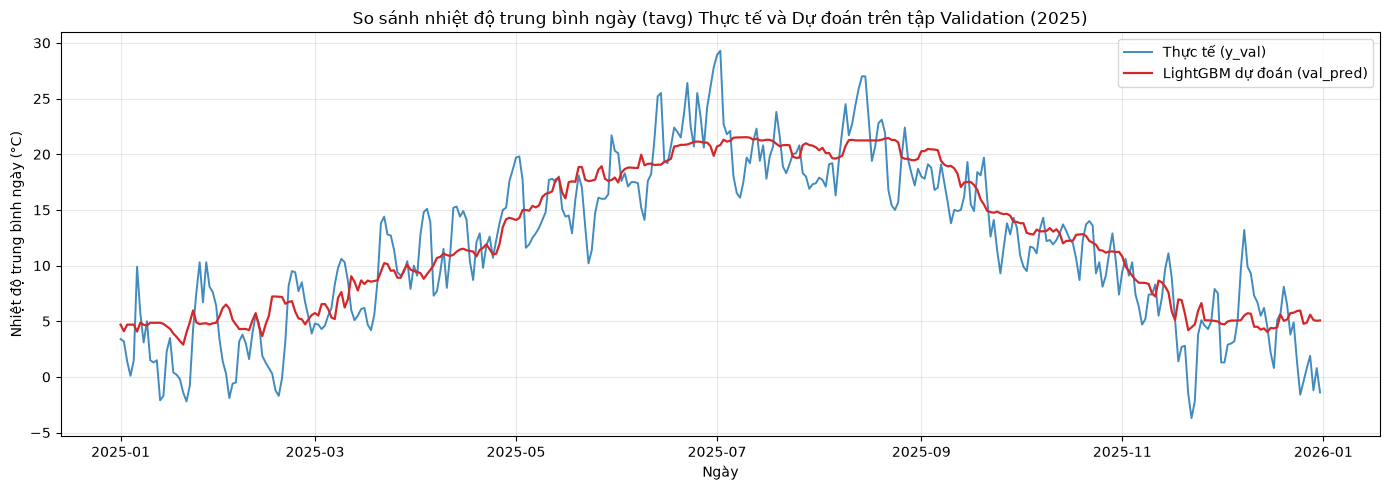

In [9]:
# Dự báo trên tập Validation (2025) từ mô hình chỉ học trên tập Train (2020-2024)
best_val_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=best_n_estimators,
    subsample_freq=1,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
    **best_params,
)
best_val_model.fit(X_train, y_train)
val_preds = best_val_model.predict(X_val)

val_mae = mean_absolute_error(y_val, val_preds)
val_rmse = root_mean_squared_error(y_val, val_preds)

print("=== KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP VALIDATION (2025) ===")
print(f"Validation MAE  : {val_mae:.4f} °C")
print(f"Validation RMSE : {val_rmse:.4f} °C (Best Score Early Stopping: {best_val_loss:.4f} °C)")

# Vẽ biểu đồ đường so sánh Dự đoán và Thực tế trên tập Validation (2025)
plt.figure(figsize=(14, 5))
plt.plot(
    val_df["date"],
    y_val.values,
    label="Thực tế (y_val)",
    color="#1f77b4",
    linewidth=1.4,
    alpha=0.85,
)
plt.plot(
    val_df["date"],
    val_preds,
    label="LightGBM dự đoán (val_pred)",
    color="#d62728",
    linewidth=1.6,
)
plt.title("So sánh nhiệt độ trung bình ngày (tavg) Thực tế và Dự đoán trên tập Validation (2025)")
plt.xlabel("Ngày")
plt.ylabel("Nhiệt độ trung bình ngày (°C)")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lightgbm_validation_2025.png", dpi=300)
plt.show()

## 5. Huấn luyện lại trên tập 2020-2025 và dự báo đầu năm 2026

In [10]:
# Khớp lại mô hình trên toàn bộ (Train + Val: 2020-2025) 
df_eval, feature_cols = create_lightgbm_features(
    df_raw, fit_mask=df_raw["split"].isin(["train", "val"])
)

train_val_df = df_eval[
    df_eval["split"].isin(["train", "val"]) & df_eval["ar_tavg_lag_365"].notna()
].reset_index(drop=True)
test_df = df_eval[df_eval["split"] == "test"].reset_index(drop=True)

final_lgbm = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=best_n_estimators,
    subsample_freq=1,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
    **best_params,
)
final_lgbm.fit(train_val_df[feature_cols], train_val_df["tavg"])

,num_leaves,4
,max_depth,2
,learning_rate,0.02
,n_estimators,213
,objective,'regression'
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,reg_alpha,1.0
,reg_lambda,1.0


In [11]:
# Dự báo 181 ngày giai đoạn 01/01/2026 - 30/06/2026
test_preds = final_lgbm.predict(test_df[feature_cols])

## 6. Xuất file kết quả

In [12]:
# File 1: Kết quả dự báo 6 tháng đầu năm 2026 (181 dòng)
forecast_2026H1_df = pd.DataFrame({
    "date": test_df["date"].dt.strftime("%Y-%m-%d"),
    "y_pred": np.round(test_preds, 4),
    "y_true": test_df["tavg"].values,
})
forecast_2026H1_df.to_csv(OUTPUT_DIR / "lightgbm_backtest.csv", index=False)

# File 2: Cấu hình tối ưu nhất của LightGBM
best_config_payload = {
    "model_name": "LightGBM",
    "best_params": best_params,
    "n_estimators": best_n_estimators,
    "fourier_k": 3,
    "feature_cols": feature_cols,
    "random_state": SEED,
    "val_2025_MAE": round(val_mae, 4),
    "val_2025_RMSE": round(val_rmse, 4),
}
with open(OUTPUT_DIR / "lightgbm_best_params.json", "w", encoding="utf-8") as f:
    json.dump(best_config_payload, f, indent=2, ensure_ascii=False)

print("\nĐã xuất thành công 2 file bàn giao tại:", OUTPUT_DIR)


Đã xuất thành công 2 file bàn giao tại: /Users/tuong/Documents/MONHOCDAIHOC/năm IV-HK1 (2026-2027)/PP Nghiên Cứu KHDL/Frankfurt_Temperature_Forecasting/results/lightgbm
